# Top 10 pairs at a motif length of 5 s

Same recording and same loudness signal as the 1–61 s search: the full `SOCAL_H_76_230427_014845.x_10kHz.wav`, reduced to RMS in non-overlapping 10 ms frames (100 Hz).

The motif length is 5 seconds (500 envelope samples). `mpx_fast` uses `minlag` equal to that length, so the two starts in a pair are at least 5 seconds apart. The next pair is skipped when it overlaps a pair already chosen.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from scipy.io import wavfile

REPO = Path("/home/yfreund/projects/panMP_whales")
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from analysis.matrix_profile import (
    format_clock as clock,
    motif_profile,
    rms_envelope,
    top_pairs,
)

WAV = Path.home() / "whale_processing/LeiData/SOCAL_H_76_230427_014845.x_10kHz.wav"
ENV_RATE = 100
LENGTH_S = 5
N_PAIRS = 10

rate, pcm = wavfile.read(WAV)
envelope = rms_envelope(pcm, rate, ENV_RATE)
window = LENGTH_S * ENV_RATE
correlation, neighbor = motif_profile(envelope, window, nthreads=8)
pairs = top_pairs(correlation, neighbor, window, N_PAIRS)
print(
    f"{WAV.name}  {len(envelope) / ENV_RATE / 60:.2f} min  "
    f"motif {LENGTH_S} s  {len(pairs)} pairs"
)


SOCAL_H_76_230427_014845.x_10kHz.wav  37.50 min  motif 5 s  10 pairs


## Times

Time A and time B are the starts of the two copies. Separation is at least 5 seconds. Correlation is the z-normalized match (1 is identical).

In [2]:
lines = [
    "| rank | time A | time B | separation (s) | correlation |",
    "|---:|---:|---:|---:|---:|",
]
for rank, (i, j, score) in enumerate(pairs, start=1):
    t_a = i / ENV_RATE
    t_b = j / ENV_RATE
    lines.append(
        f"| {rank} | {clock(t_a)} | {clock(t_b)} | {t_b - t_a:.1f} | {score:.3f} |"
    )
display(Markdown("\n".join(lines)))


| rank | time A | time B | separation (s) | correlation |
|---:|---:|---:|---:|---:|
| 1 | 11:14.9 | 11:49.4 | 34.5 | 0.610 |
| 2 | 34:04.1 | 34:27.5 | 23.5 | 0.605 |
| 3 | 15:25.1 | 16:32.4 | 67.3 | 0.552 |
| 4 | 11:25.0 | 11:59.4 | 34.4 | 0.547 |
| 5 | 7:58.4 | 8:07.2 | 8.8 | 0.545 |
| 6 | 5:54.9 | 6:08.5 | 13.7 | 0.537 |
| 7 | 9:26.9 | 10:01.5 | 34.6 | 0.522 |
| 8 | 7:01.9 | 7:11.6 | 9.6 | 0.516 |
| 9 | 14:29.1 | 14:42.7 | 13.6 | 0.515 |
| 10 | 0:05.4 | 33:16.0 | 1990.7 | 0.512 |

## Where they sit

Each color is one pair. The two shaded spans are the two 5-second copies.

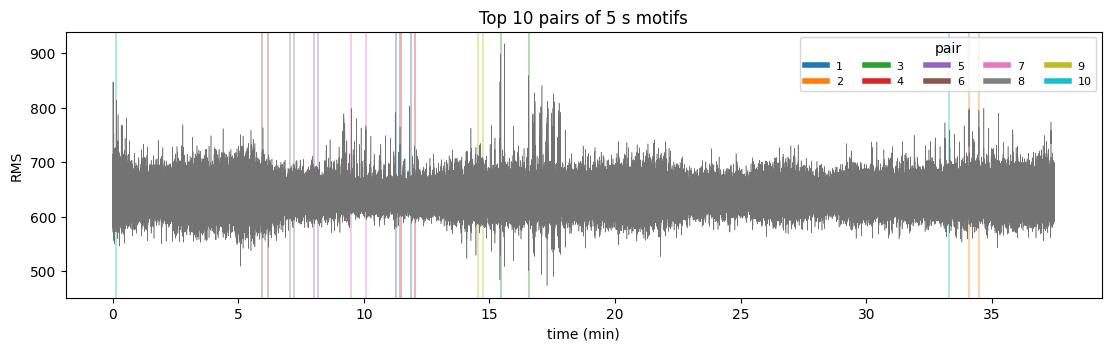

In [3]:
colors = plt.cm.tab10(np.arange(len(pairs)))
time = np.arange(len(envelope)) / ENV_RATE / 60.0
fig, ax = plt.subplots(figsize=(11, 3.4), layout="constrained")
ax.plot(time, envelope, color="0.45", lw=0.4)
for rank, ((i, j, _score), color) in enumerate(zip(pairs, colors), start=1):
    for start in (i, j):
        ax.axvspan(
            start / ENV_RATE / 60.0,
            (start + window) / ENV_RATE / 60.0,
            color=color,
            alpha=0.35,
            lw=0,
        )
    ax.plot([], [], color=color, lw=4, label=str(rank))
ax.set_xlabel("time (min)")
ax.set_ylabel("RMS")
ax.set_title("Top 10 pairs of 5 s motifs")
ax.legend(title="pair", ncol=5, fontsize=8)
plt.show()


## The ten pairs

Each panel is the two 5-second RMS envelopes, z-scored. The legend is the start time of each copy.

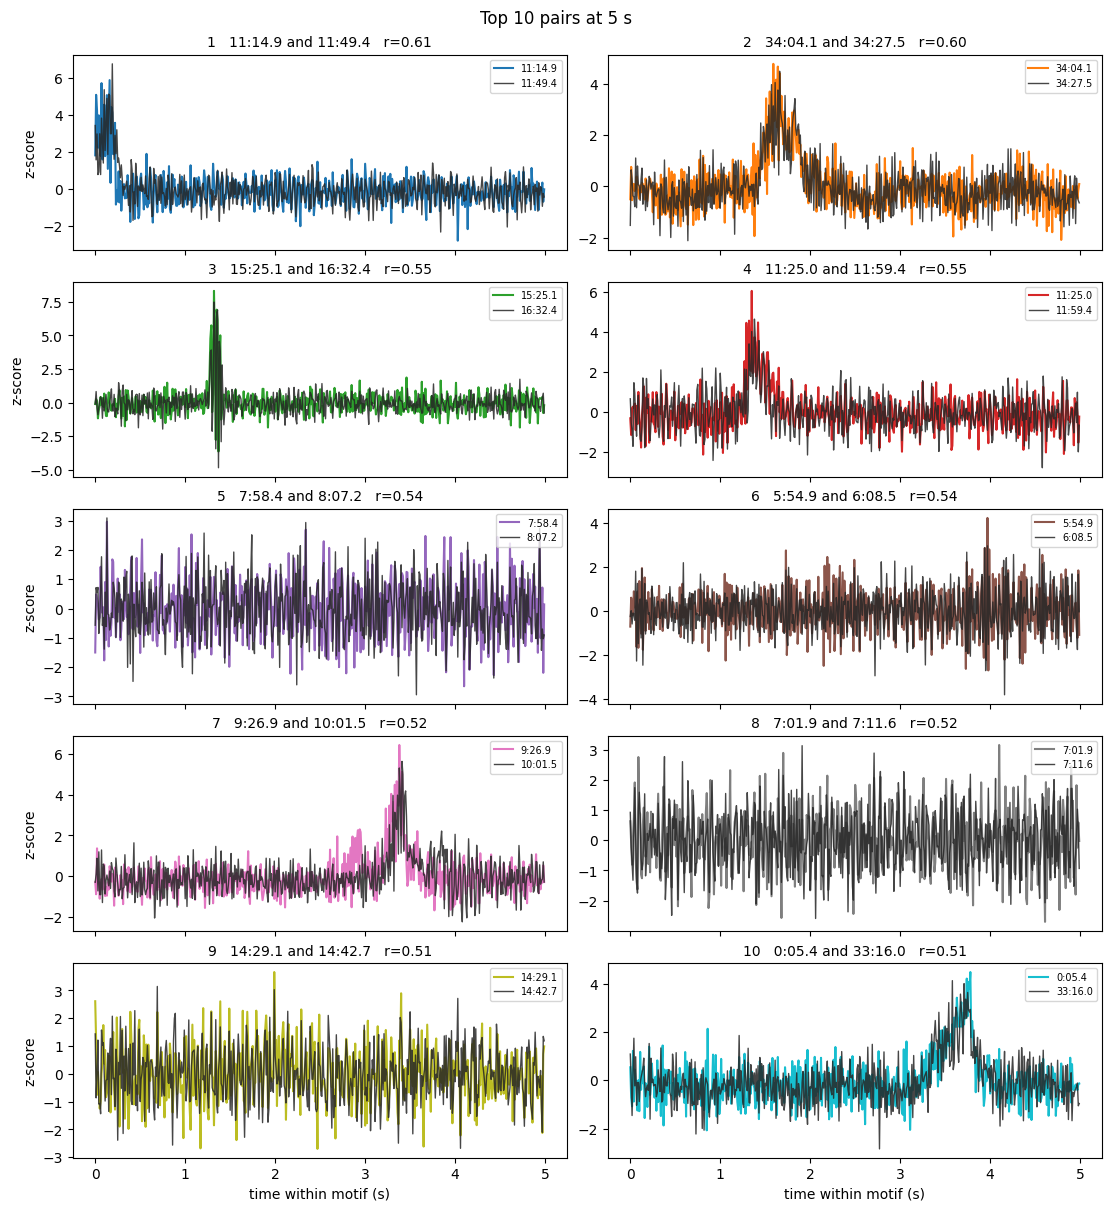

In [4]:
def zscore(values):
    values = np.asarray(values, dtype=np.float64)
    return (values - values.mean()) / (values.std() + 1e-12)

within = np.arange(window) / ENV_RATE
fig, axes = plt.subplots(5, 2, figsize=(11, 12), sharex=True, layout="constrained")
for ax, (rank, (i, j, score), color) in zip(
    axes.ravel(), ((n, pair, c) for n, (pair, c) in enumerate(zip(pairs, colors), start=1))
):
    ax.plot(within, zscore(envelope[i : i + window]), color=color, label=clock(i / ENV_RATE))
    ax.plot(
        within,
        zscore(envelope[j : j + window]),
        color="0.15",
        lw=1.0,
        alpha=0.85,
        label=clock(j / ENV_RATE),
    )
    ax.set_title(
        f"{rank}   {clock(i / ENV_RATE)} and {clock(j / ENV_RATE)}   r={score:.2f}",
        fontsize=10,
    )
    ax.legend(fontsize=7, loc="upper right")
for ax in axes[-1]:
    ax.set_xlabel("time within motif (s)")
for ax in axes[:, 0]:
    ax.set_ylabel("z-score")
fig.suptitle("Top 10 pairs at 5 s")
plt.show()
